# Capitolo 4 — Trasformazioni, stima robusta e warping
Arcangelo Distante e Cosimo Distante — **Computer Vision**

Questo notebook usa esclusivamente segnali, punti e camere sintetici, definiti nel codice. Non contiene immagini esterne, benchmark, addestramento o misure di una camera reale. Le quantità calcolate illustrano i modelli e le loro condizioni di validità.

## Avvio e materiali
In Google Colab aprire questo file, selezionare un runtime **CPU** e avviare le celle dall’alto. Non servono GPU, file da caricare né download di dati. Sono necessarie NumPy e Matplotlib, normalmente già disponibili in Colab; in un ambiente nuovo installarle prima dell’esecuzione con `%pip install numpy matplotlib`. In locale è adeguato Python 3 con le stesse dipendenze.

La cartella `output_capitolo04` viene creata nello stesso runtime. Alla fine contiene figure, eventuali CSV e `metriche.json`. Per conservarla in Colab scaricarla dal pannello File prima di chiudere il runtime, oppure copiarla nel proprio Drive dopo averlo montato. Il riavvio elimina le variabili: rieseguire dalla prima cella. Per ogni esperimento modificato conservare parametri, seed e output in una nuova cartella.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

OUTPUT = Path('output_capitolo04')
OUTPUT.mkdir(exist_ok=True)
rng = np.random.default_rng(2026)
metriche = {}
plt.rcParams.update({'font.size': 10, 'figure.figsize': (7, 4)})

def salva_figura(nome):
    plt.tight_layout()
    plt.savefig(OUTPUT / (nome + '.png'), dpi=160)
    plt.show()
    plt.close()

def proietta(P, X):
    q = np.c_[X, np.ones(len(X))] @ P.T
    return q[:, :2] / q[:, 2:]


In [2]:
def applica_H(H, p):
    q = np.c_[p, np.ones(len(p))] @ H.T
    with np.errstate(divide='ignore', invalid='ignore'):
        return q[:, :2] / q[:, 2:]

def normalizza(p):
    centro = p.mean(axis=0)
    distanza = np.linalg.norm(p - centro, axis=1).mean()
    if distanza < 1e-12:
        raise ValueError('Configurazione priva di estensione')
    s = np.sqrt(2) / distanza
    T = np.array([[s, 0, -s*centro[0]], [0, s, -s*centro[1]], [0, 0, 1.]])
    return applica_H(T, p), T

def dlt(p, q):
    if len(p) < 4:
        raise ValueError('Servono almeno quattro corrispondenze')
    pn, T = normalizza(np.asarray(p, dtype=float))
    qn, U = normalizza(np.asarray(q, dtype=float))
    A = []
    for (x, y), (u, v) in zip(pn, qn):
        A.extend([[-x, -y, -1, 0, 0, 0, u*x, u*y, u],
                  [0, 0, 0, -x, -y, -1, v*x, v*y, v]])
    A = np.asarray(A)
    if np.linalg.matrix_rank(A) < 8:
        raise ValueError('Configurazione degenere')
    # full_matrices=True conserva la direzione nulla anche con una matrice 8x9.
    _, _, Vt = np.linalg.svd(A, full_matrices=True)
    H = np.linalg.inv(U) @ Vt[-1].reshape(3, 3) @ T
    return H / np.linalg.norm(H)


## N4.A1 — DLT normalizzato su corrispondenze esatte

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

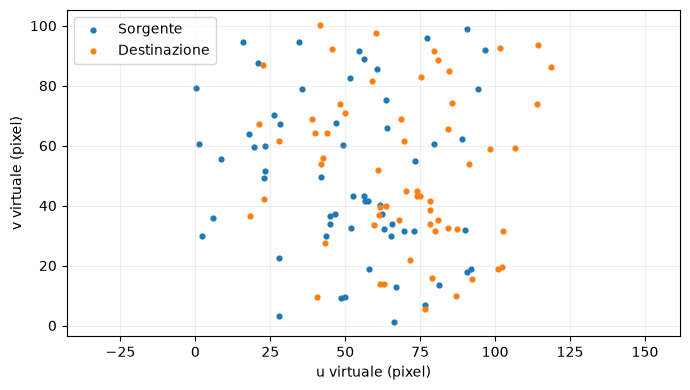

In [3]:
H_vera = np.array([[1.05, 0.12, 12.], [-0.05, 0.95, 8.], [0.001, -0.0005, 1.]])
p = rng.uniform(0, 100, size=(60, 2))
q_veri = applica_H(H_vera, p)
H_esatta = dlt(p, q_veri)
test = rng.uniform(0, 100, size=(200, 2))
errore = np.linalg.norm(applica_H(H_esatta, test)-applica_H(H_vera, test), axis=1)
metriche['mediana_DLT_esatto_pixel'] = float(np.median(errore))
plt.scatter(*p.T, s=12, label='Sorgente')
plt.scatter(*q_veri.T, s=12, label='Destinazione')
plt.xlabel('u virtuale (pixel)'); plt.ylabel('v virtuale (pixel)')
plt.legend(); plt.axis('equal'); plt.grid(alpha=0.2)
salva_figura('A1_corrispondenze')


**Domande**

1. Come confrontare due omografie definite a meno di scala?
2. Perché la riuscita con dati esatti non dimostra robustezza agli outlier?

## N4.A2 — Consenso robusto e validazione separata

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

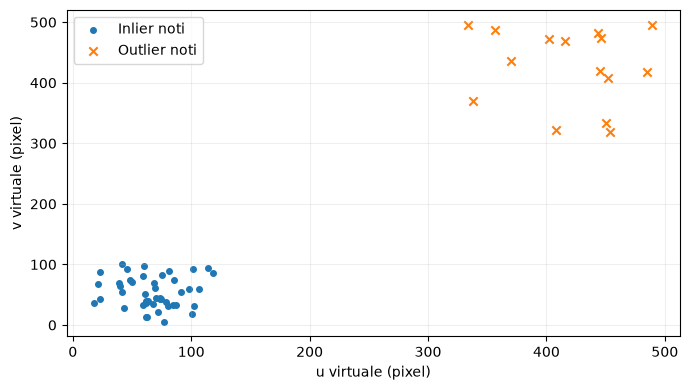

{'mediana_DLT_esatto_pixel': 1.5888218580782548e-14, 'mediana_test_globale_pixel': 559.9980738364352, 'mediana_test_robusta_pixel': 1.4484830223734477e-14, 'inlier_selezionati': 45, 'precisione_consenso': 1.0, 'richiamo_consenso': 1.0}


In [4]:
q = q_veri.copy()
veri_inlier = np.ones(len(p), dtype=bool)
veri_inlier[-15:] = False
q[~veri_inlier] = rng.uniform(300, 500, size=(15, 2))
H_globale = dlt(p, q)
migliore = np.zeros(len(p), dtype=bool)
for _ in range(100):
    indici = rng.choice(len(p), 4, replace=False)
    try:
        candidato = dlt(p[indici], q[indici])
        r = np.linalg.norm(applica_H(candidato, p)-q, axis=1)
        mask = np.isfinite(r) & (r < 1.0)
        if mask.sum() > migliore.sum():
            migliore = mask
    except (ValueError, np.linalg.LinAlgError):
        continue
if migliore.sum() < 4:
    raise RuntimeError('Nessun consenso sufficiente: aumentare il budget')
H_robusta = dlt(p[migliore], q[migliore])
target_test = applica_H(H_vera, test)
for nome, H in [('globale', H_globale), ('robusta', H_robusta)]:
    r = np.linalg.norm(applica_H(H, test)-target_test, axis=1)
    metriche['mediana_test_'+nome+'_pixel'] = float(np.median(r))
metriche['inlier_selezionati'] = int(migliore.sum())
metriche['precisione_consenso'] = float((migliore & veri_inlier).sum()/migliore.sum())
metriche['richiamo_consenso'] = float((migliore & veri_inlier).sum()/veri_inlier.sum())
plt.scatter(*q[veri_inlier].T, label='Inlier noti', s=16)
plt.scatter(*q[~veri_inlier].T, label='Outlier noti', marker='x')
plt.xlabel('u virtuale (pixel)'); plt.ylabel('v virtuale (pixel)')
plt.legend(); plt.grid(alpha=0.2)
salva_figura('A2_contaminazione')
print(metriche)


**Domande**

1. Confrontare fit globale e fit robusto sui punti di test esclusi dalla stima.
2. Modificare quota di contaminazione, soglia e seed: quali conclusioni richiedono più repliche?

## N4.A3 — Interpolazione e significato del backward mapping

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

Pesi: [0.1875 0.0625 0.5625 0.1875] valore: 48.75


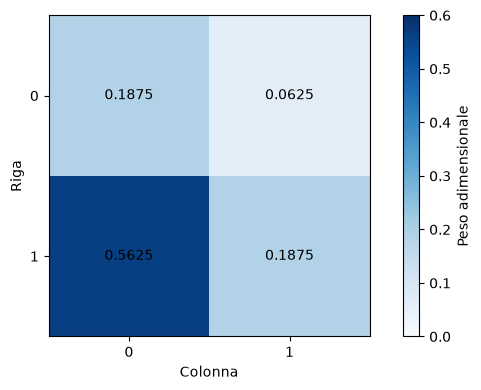

In [5]:
alpha, beta = 0.25, 0.75
pesi = np.array([(1-alpha)*(1-beta), alpha*(1-beta), (1-alpha)*beta, alpha*beta])
valori = np.array([10., 30., 50., 90.])
metriche['somma_pesi_bilineari'] = float(pesi.sum())
metriche['interpolazione_bilineare'] = float(pesi @ valori)
print('Pesi:', pesi, 'valore:', metriche['interpolazione_bilineare'])
plt.imshow(pesi.reshape(2,2), cmap='Blues', vmin=0, vmax=0.6)
for i, valore in enumerate(pesi):
    plt.text(i%2, i//2, f'{valore:.4f}', ha='center', va='center')
plt.xticks([0,1]); plt.yticks([0,1]); plt.xlabel('Colonna'); plt.ylabel('Riga')
plt.colorbar(label='Peso adimensionale')
salva_figura('A3_bilineare')


**Domande**

1. Ricavare i pesi e verificare il valore interpolato.
2. Distinguere l’inversa della mappa geometrica dall’interpolazione e dal filtro anti-aliasing.

## Conservare i risultati

La cella seguente salva le quantità calcolate durante questa esecuzione. I valori del file descrivono questi dati sintetici e questi parametri. Non rappresentano prestazioni su dati reali.

In [6]:
with (OUTPUT / 'metriche.json').open('w') as f_json:
    json.dump(metriche, f_json, indent=2, allow_nan=False)
print('Output salvati in:', OUTPUT)

Output salvati in: output_capitolo04
